In [1]:
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from statsmodels.tsa.seasonal import STL
import seaborn as sns
import numpy as np
from datetime import timedelta
from sklearn.preprocessing import LabelEncoder
import category_encoders as ce
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score,root_mean_squared_error
import xgboost as xgb
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('routes.csv')

In [3]:
columns_order = [
    "BOOKING_ID", "ITEM_NO", "ROUTE", "AIRLINE", "ADULT", "CHILD", "INFANT", 
    "COST", "PRICE", "BOOKING_CLASS", "CABIN_CLASS", "FARE_TYPE", 
    "BOOKED_DATE", "DEP_DATE", "DES_DATE", "DAYS_IN_BETWEEN"
]

df = df[columns_order]
df.head()

,BOOKING_ID,ITEM_NO,ROUTE,AIRLINE,ADULT,CHILD,INFANT,COST,PRICE,BOOKING_CLASS,CABIN_CLASS,FARE_TYPE,BOOKED_DATE,DEP_DATE,DES_DATE,DAYS_IN_BETWEEN
0,10006,1.0,LHR -> MUC -> MUC -> DEL -> DEL -> FRA -> FRA ...,LH,2.0,0.0,0.0,825.08,833.38,K,Economy,PUB,2018-11-15,2019-09-01,2019-09-09,290
1,10007,1.0,LHR -> DEL -> DEL -> LHR,BA,2.0,0.0,0.0,1444.84,1487.94,N,Economy,PUB,2018-11-15,2019-08-20,2019-08-29,278
2,10012,1.0,LHR -> DEL -> DEL -> LHR,BA,2.0,0.0,0.0,1986.64,2043.94,T,PremiumEconomy,PVT,2018-11-16,2019-08-20,2019-08-29,277
3,10013,1.0,LHR -> DEL -> DEL -> LHR,BA,2.0,0.0,0.0,1235.04,1267.64,Q,Economy,PUB,2018-11-19,2019-01-01,2019-01-10,43
4,10014,1.0,LHR -> FRA -> FRA -> DEL -> DEL -> FRA -> FRA ...,LH,2.0,0.0,0.0,1094.28,1116.78,V,Economy,PUB,2018-11-19,2019-10-19,2019-10-28,334


In [4]:
# Group by AIRLINE and count the number of records for each airline
airline_counts = df.groupby('AIRLINE').size().reset_index(name='count')

# Sort by count in descending order and get the top 5 airlines
top_5_airlines = airline_counts.sort_values(by='count', ascending=False).head(5)['AIRLINE']

# Filter the original DataFrame to include only the top 5 airlines
filtered_df = df[df['AIRLINE'].isin(top_5_airlines)]
print(filtered_df)

         BOOKING_ID  ITEM_NO  \
1             10007      1.0   
2             10012      1.0   
3             10013      1.0   
6             10017      1.0   
7             10018      1.0   
...             ...      ...   
1108205      299743      4.0   
1108206      299744      1.0   
1108207      299746      1.0   
1108208      299746      2.0   
1108209      299747      1.0   

                                                     ROUTE AIRLINE  ADULT  \
1                                 LHR -> DEL -> DEL -> LHR      BA    2.0   
2                                 LHR -> DEL -> DEL -> LHR      BA    2.0   
3                                 LHR -> DEL -> DEL -> LHR      BA    2.0   
6                                 LHR -> DEL -> DEL -> LHR      BA    1.0   
7                                 LHR -> DEL -> DEL -> LHR      BA    1.0   
...                                                    ...     ...    ...   
1108205  STN -> DXB -> DXB -> MLE -> MLE -> DXB -> DXB ...      EK    2.0   

In [5]:
route_counts = filtered_df.groupby('ROUTE').size().reset_index(name='count')
top_20_routes = route_counts.sort_values(by='count', ascending=False).head(20)['ROUTE']

# Filter the original DataFrame to include only the top 5 routes
df = filtered_df[filtered_df['ROUTE'].isin(top_20_routes)]
print(df)

         BOOKING_ID  ITEM_NO  \
21            10068      1.0   
31            10088      1.0   
32            10089      1.0   
33            10090      1.0   
34            10091      1.0   
...             ...      ...   
1108187      299738      3.0   
1108200      299742      1.0   
1108201      299742      2.0   
1108204      299743      3.0   
1108209      299747      1.0   

                                                     ROUTE AIRLINE  ADULT  \
21                                LHR -> CMB -> CMB -> LHR      UL    2.0   
31                                LGW -> ANU -> ANU -> LGW      BA    1.0   
32                                LGW -> ANU -> ANU -> LGW      VS    2.0   
33                                LGW -> ANU -> ANU -> LGW      BA    2.0   
34                                LGW -> ANU -> ANU -> LGW      BA    2.0   
...                                                    ...     ...    ...   
1108187                           LHR -> CMB -> CMB -> LHR      UL    2.0   

In [6]:
df = df.apply(lambda col: col.str.lower() if col.dtype == 'object' else col)

In [7]:
# Group by ROUTE and aggregate min and max dates
date_ranges = df.groupby('ROUTE').agg(
    BOOKED_DATE_MIN=('BOOKED_DATE', 'min'),
    BOOKED_DATE_MAX=('BOOKED_DATE', 'max'),
    DEP_DATE_MIN=('DEP_DATE', 'min'),
    DEP_DATE_MAX=('DEP_DATE', 'max')
).reset_index()

print(date_ranges)

                                                ROUTE BOOKED_DATE_MIN  \
0   bhx -> dxb -> dxb -> mle -> mle -> dxb -> dxb ...      2019-10-15   
1                                          cmb -> mle      2019-07-09   
2                            lgw -> anu -> anu -> lgw      2019-04-04   
3                            lgw -> bgi -> bgi -> lgw      2019-04-25   
4                            lgw -> cun -> cun -> lgw      2019-05-09   
5   lgw -> doh -> doh -> mle -> mle -> doh -> doh ...      2019-11-16   
6   lgw -> dxb -> dxb -> mle -> mle -> dxb -> dxb ...      2019-06-10   
7                            lgw -> mru -> mru -> lgw      2019-11-04   
8                            lgw -> uvf -> uvf -> lgw      2019-06-04   
9                            lhr -> bgi -> bgi -> lhr      2019-12-08   
10                           lhr -> cmb -> cmb -> lhr      2019-02-19   
11  lhr -> cmb -> cmb -> mle -> mle -> cmb -> cmb ...      2019-06-23   
12  lhr -> doh -> doh -> mle -> mle -> doh -> doh .

In [8]:
df.head()

,BOOKING_ID,ITEM_NO,ROUTE,AIRLINE,ADULT,CHILD,INFANT,COST,PRICE,BOOKING_CLASS,CABIN_CLASS,FARE_TYPE,BOOKED_DATE,DEP_DATE,DES_DATE,DAYS_IN_BETWEEN
21,10068,1.0,lhr -> cmb -> cmb -> lhr,ul,2.0,0.0,0.0,1117.64,1131.64,s,economy,pub,2019-02-19,2019-10-27,2019-11-03,250
31,10088,1.0,lgw -> anu -> anu -> lgw,ba,1.0,0.0,0.0,588.00,646.80,n,economy,net,2019-04-04,2020-03-17,2020-03-25,348
32,10089,1.0,lgw -> anu -> anu -> lgw,vs,2.0,0.0,0.0,1380.24,1493.34,o,economy,itx,2019-04-04,2020-02-08,2020-02-23,310
33,10090,1.0,lgw -> anu -> anu -> lgw,ba,2.0,0.0,0.0,998.24,1054.04,q,economy,pub,2019-04-04,2020-02-08,2020-02-16,310
34,10091,1.0,lgw -> anu -> anu -> lgw,ba,2.0,0.0,0.0,968.24,1019.54,o,economy,pub,2019-04-04,2020-01-11,2020-01-19,282


In [9]:
df['BOOKED_DATE'] = pd.to_datetime(df['BOOKED_DATE'])
df['BOOKED_YEAR'] = df['BOOKED_DATE'].dt.year
df['BOOKED_MONTH'] = df['BOOKED_DATE'].dt.month
df['BOOKED_DAY'] = df['BOOKED_DATE'].dt.day
df['DEP_DATE'] = pd.to_datetime(df['DEP_DATE'])
df['DEP_YEAR'] = df['DEP_DATE'].dt.year
df['DEP_MONTH'] = df['DEP_DATE'].dt.month
df['DEP_DAY'] = df['DEP_DATE'].dt.day
df['DES_DATE'] = pd.to_datetime(df['DES_DATE'])
df['DES_YEAR'] = df['DES_DATE'].dt.year
df['DES_MONTH'] = df['DES_DATE'].dt.month
df['DES_DAY'] = df['DES_DATE'].dt.day
df['DEP_DES_DAYS'] = (df['DES_DATE'] - df['DEP_DATE']).dt.days
df['DAY_OF_WEEK'] = df['DEP_DATE'].dt.dayofweek

df['NEW_BOOKED_DATE'] = df['BOOKED_DATE'].astype('int64')
df['NEW_DEP_DATE'] = df['DEP_DATE'].astype('int64')
df['NEW_DES_DATE'] = df['DES_DATE'].astype('int64')

In [10]:
def mark_high_season_events(df, dep_date_col='DEP_DATE'):
    # High seasons dictionary organized by region
    high_seasons = {
        'Middle_East': {
            'Abu_Dhabi_F1': ['2024-12-06', '2024-12-08', '2025-10-05', '2026-10-25'],
            'Eid_Middle_East': ['2025-03-30', '2025-03-31', '2026-03-19', '2026-03-20']
        },
        'Asia': {
            'Singapore_F1': ['2024-09-20', '2024-09-22', '2025-09-07', '2026-10-04'],
            'TET_Vietnam': ['2025-01-29', '2026-01-17'],
            'Chinese_New_Year': ['2024-02-10', '2025-01-29', '2026-02-17'],
            'Golden_Week_Japan': ['2024-04-29', '2024-05-05', '2025-04-29', '2025-05-05', '2026-04-29', '2026-05-05'],
            'Mid_Autumn_Festival': ['2024-09-17', '2025-10-06', '2026-09-25'],
            'Golden_Week_China': ['2024-10-01', '2024-10-07', '2025-10-01', '2025-10-07', '2026-10-01', '2026-10-07']
        },
        'Africa': {
            'Tanzania_High_Season': ['2024-01-01', '2024-02-28', '2024-06-01', '2024-10-31'],
            'South_Africa_High_Season': ['2024-12-01', '2025-03-31']
        },
        'Global': {
            'New_Years_Day': ['2024-01-01', '2025-01-01', '2026-01-01'],
            'Easter': ['2024-03-31', '2025-04-20', '2026-04-05'],
            'Labor_Day': ['2024-05-01', '2025-05-01', '2026-05-01'],
            'Ramadan_and_Eid_al_Fitr': ['2024-03-10', '2024-04-09', '2025-03-30', '2025-04-29', '2026-03-19', '2026-04-18'],
            'US_Independence_Day': ['2024-07-04', '2025-07-04', '2026-07-04'],
            'Bastille_Day': ['2024-07-14', '2025-07-14', '2026-07-14'],
            'Diwali': ['2024-11-01', '2025-10-21', '2026-11-08'],
            'Thanksgiving_US': ['2024-11-28', '2025-11-27', '2026-11-26'],
            'Christmas': ['2024-12-25', '2025-12-25', '2026-12-25'],
            'Boxing_Day': ['2024-12-26', '2025-12-26', '2026-12-26'],
            'Hanukkah': ['2024-12-25', '2025-12-14', '2026-12-04']
        },
        'Europe': {
            'Oktoberfest': ['2024-09-21', '2024-10-06', '2025-09-20', '2025-10-05', '2026-09-19', '2026-10-04'],
            'La_Tomatina': ['2024-08-28', '2025-08-27', '2026-08-26'],
            'Venice_Carnival': ['2024-02-10', '2025-02-09', '2026-02-08'],
            'St_Patricks_Day': ['2024-03-17', '2025-03-17', '2026-03-17'],
            'Midsummer_Eve': ['2024-06-23', '2025-06-23', '2026-06-23'],
            'Edinburgh_Festival_Fringe': ['2024-08-02', '2024-08-26', '2025-08-01', '2025-08-25', '2026-08-07', '2026-08-31'],
            'Sant_Jordis_Day': ['2024-04-23', '2025-04-23', '2026-04-23'],
            'Running_of_the_Bulls': ['2024-07-06', '2024-07-14', '2025-07-06', '2025-07-14', '2026-07-06', '2026-07-14'],
            'Battle_of_the_Oranges': ['2024-02-13', '2025-02-11', '2026-02-10']
        }
    }

    # Convert event dates to datetime objects with 2-3 day ranges
    for region, events in high_seasons.items():
        for event, dates in events.items():
            extended_dates = []
            for date in dates:
                event_date = pd.to_datetime(date)
                # Extend 3 days before and after the event date
                for i in range(-3, 4):
                    extended_dates.append(event_date + timedelta(days=i))
            high_seasons[region][event] = extended_dates

    # Function to check if a date falls within a high-season period
    def is_high_season(date, high_season_dates):
        return date in high_season_dates

    # Event mapping with regions
    event_mapping = {
        'Middle_East': {
            'Abu_Dhabi_F1': 1,
            'Eid_Middle_East': 2
        },
        'Asia': {
            'Singapore_F1': 3,
            'TET_Vietnam': 4,
            'Chinese_New_Year': 5,
            'Golden_Week_Japan': 6,
            'Mid_Autumn_Festival': 7,
            'Golden_Week_China': 8
        },
        'Africa': {
            'Tanzania_High_Season': 9,
            'South_Africa_High_Season': 10
        },
        'Global': {
            'New_Years_Day': 11,
            'Easter': 12,
            'Labor_Day': 13,
            'Ramadan_and_Eid_al_Fitr': 14,
            'US_Independence_Day': 15,
            'Bastille_Day': 16,
            'Diwali': 17,
            'Thanksgiving_US': 18,
            'Christmas': 19,
            'Boxing_Day': 20,
            'Hanukkah': 21
        },
        'Europe': {
            'Oktoberfest': 22,
            'La_Tomatina': 23,
            'Venice_Carnival': 24,
            'St_Patricks_Day': 25,
            'Midsummer_Eve': 26,
            'Edinburgh_Festival_Fringe': 27,
            'Sant_Jordis_Day': 28,
            'Running_of_the_Bulls': 29,
            'Battle_of_the_Oranges': 30
        }
    }

    # Initialize the column with 0
    df['HIGH_SEASON_EVENTS'] = 0

    # Iterate through high seasons and mark relevant rows with unique values considering regions
    for region, events in high_seasons.items():
        for event, dates in events.items():
            df.loc[df[dep_date_col].apply(lambda x: is_high_season(x, dates)), 'HIGH_SEASON_EVENTS'] = event_mapping[region][event]

    return df

# Example usage
# df = mark_high_season_events(df)


In [11]:
df = mark_high_season_events(df, dep_date_col='DEP_DATE')
df['TOTAL_PASSENGERS'] = df['ADULT'] + df['CHILD'] + df['INFANT']
df['BCLASS_DEP_DATE'] = df['BOOKING_CLASS'].astype(str) + '_' + df['DEP_MONTH'].astype(str) + '_' + df['DEP_DAY'].astype(str)
df['AIRLINE_ROUTE_BCLASS_CCLASS'] = df['AIRLINE'].astype(str) + '_' + df['ROUTE'].astype(str) + '_' + df['BOOKING_CLASS'].astype(str) + '_' + df['CABIN_CLASS'].astype(str)
df['BOOKING_CLASS_DAYS_IN_BETWEEN'] = df['BOOKING_CLASS'].astype(str) + '_' + df['DAYS_IN_BETWEEN'].astype(str)
df['DEP_MONTH_ROUTE'] = df['DEP_MONTH'].astype(str) + '_' + df['ROUTE'].astype(str)
df['MONTHROUTE_BCLASSMONTHS'] = df['DEP_MONTH_ROUTE'].astype(str) + '_' + df['BOOKING_CLASS'].astype(str) + '_' + df['BOOKED_MONTH'].astype(str)
df['MONTH_ROUTE_FARETYPE_BCLASSDAYS'] = df['BOOKED_MONTH'].astype(str) + '_' + df['ROUTE'].astype(str) + '_' + df['FARE_TYPE'].astype(str) + '_' + df['BOOKING_CLASS_DAYS_IN_BETWEEN'].astype(str)

In [12]:
df = df.apply(lambda col: col.str.lower() if col.dtype == 'object' else col)

df['ADULT'] = df['ADULT'].astype(float)
df['CHILD'] = df['CHILD'].astype(float)
df['INFANT'] = df['INFANT'].astype(float)
df['COST'] = df['COST'].astype(float)
df['PRICE'] = df['PRICE'].astype(float)
df['DAYS_IN_BETWEEN'] = df['DAYS_IN_BETWEEN'].astype(int)
df['TOTAL_PASSENGERS'] = df['TOTAL_PASSENGERS'].astype(float)
df['DEP_DES_DAYS'] = df['DEP_DES_DAYS'].astype(int)
df['DAY_OF_WEEK'] = df['DAY_OF_WEEK'].astype(int)

df['ROUTE'] = df['ROUTE'].str.strip().str.lower()
df['AIRLINE'] = df['AIRLINE'].str.strip().str.lower()
df['BOOKING_CLASS'] = df['BOOKING_CLASS'].str.strip().str.lower()
df['CABIN_CLASS'] = df['CABIN_CLASS'].str.strip().str.lower()
df['FARE_TYPE'] = df['FARE_TYPE'].str.strip().str.lower()

In [13]:
df.to_csv('df.csv')

In [14]:
label_features = ['ROUTE', 'AIRLINE', 'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS', 
                  'MONTHROUTE_BCLASSMONTHS', 'CABIN_CLASS', 'BOOKING_CLASS', 'FARE_TYPE', 'MONTH_ROUTE_FARETYPE_BCLASSDAYS', 'DEP_MONTH_ROUTE']

label_encoders = {}
for feature in label_features:
    le = LabelEncoder()
    df[feature] = le.fit_transform(df[feature])
    label_encoders[feature] = le


In [15]:
df.head()

,BOOKING_ID,ITEM_NO,ROUTE,AIRLINE,ADULT,CHILD,INFANT,COST,PRICE,BOOKING_CLASS,...,NEW_DEP_DATE,NEW_DES_DATE,HIGH_SEASON_EVENTS,TOTAL_PASSENGERS,BCLASS_DEP_DATE,AIRLINE_ROUTE_BCLASS_CCLASS,BOOKING_CLASS_DAYS_IN_BETWEEN,DEP_MONTH_ROUTE,MONTHROUTE_BCLASSMONTHS,MONTH_ROUTE_FARETYPE_BCLASSDAYS
21,10068,1.0,10,3,2.0,0.0,0.0,1117.64,1131.64,17,...,1572134400000000000,1572739200000000000,0,2.0,4693,402,s_250,10,1164,67303
31,10088,1.0,2,0,1.0,0.0,0.0,588.00,646.80,12,...,1584403200000000000,1585094400000000000,0,1.0,3258,10,n_348,102,10816,92662
32,10089,1.0,2,4,2.0,0.0,0.0,1380.24,1493.34,13,...,1581120000000000000,1582416000000000000,0,2.0,3615,448,o_310,82,8618,92247
33,10090,1.0,2,0,2.0,0.0,0.0,998.24,1054.04,15,...,1581120000000000000,1581811200000000000,0,2.0,4096,13,q_310,82,8630,92710
34,10091,1.0,2,0,2.0,0.0,0.0,968.24,1019.54,13,...,1578700800000000000,1579392000000000000,0,2.0,3559,11,o_282,62,6649,92708


In [16]:
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.85)
    IQR = Q3 - Q1
    return df[(df[column] >= (Q1 - 1.5 * IQR)) & (df[column] <= (Q3 + 1.5 * IQR))]

df = remove_outliers(df, 'COST')
# df = remove_outliers(df, 'PRICE')

In [17]:
features = ['ADULT', 'CHILD','ROUTE','AIRLINE','BOOKING_CLASS','CABIN_CLASS','FARE_TYPE', 'NEW_BOOKED_DATE', 'NEW_DEP_DATE', 'NEW_DES_DATE','DEP_DES_DAYS','DAYS_IN_BETWEEN','TOTAL_PASSENGERS'
            ,'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS','HIGH_SEASON_EVENTS', 'DEP_MONTH_ROUTE', 'DAY_OF_WEEK'
           ]

target = 'COST'

train_df = df[df['BOOKED_DATE'].dt.year < 2023]
test_df = df[df['BOOKED_DATE'].dt.year >= 2023]
test_df = test_df[test_df['BOOKED_DATE'].dt.year < 2025]

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]


In [18]:
# # Perform a 90/10 split for training and testing
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# # Align the test set with the train set
# X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [19]:
X_train.shape

(275482, 18)

In [20]:
X_test.shape

(106120, 18)

In [ ]:
# Initialize and train the model
model = XGBRegressor(n_estimators=1000, max_depth=10, learning_rate=0.01, subsample=0.8, colsample_bytree=0.8)

model.fit(X_train, y_train)

# Predict on the test set
predictions = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse}')

rmse = root_mean_squared_error(y_test, predictions)
print(f'Root Mean Squared Error: {rmse}')

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

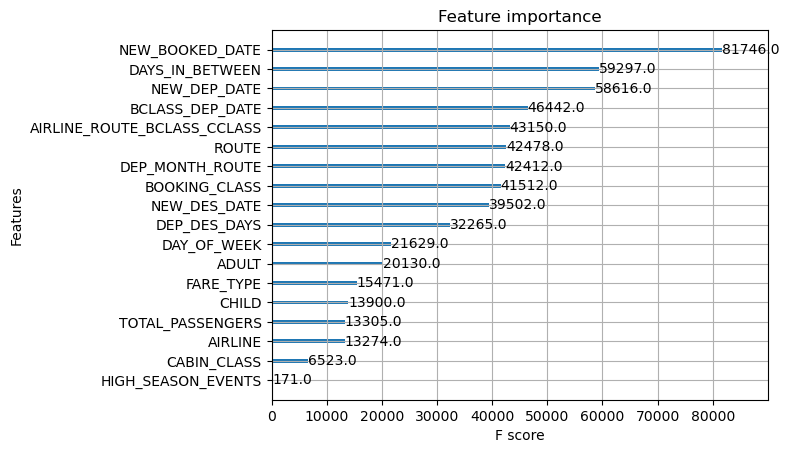

In [22]:
xgb.plot_importance(model)

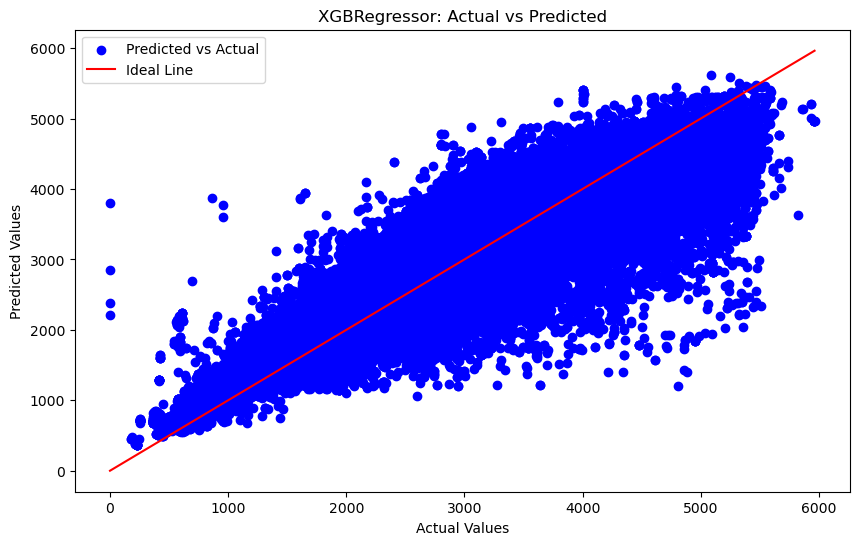

In [23]:
# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(y_test, predictions, color="blue", label="Predicted vs Actual")
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color="red", label="Ideal Line")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("XGBRegressor: Actual vs Predicted")
plt.legend()
plt.show()

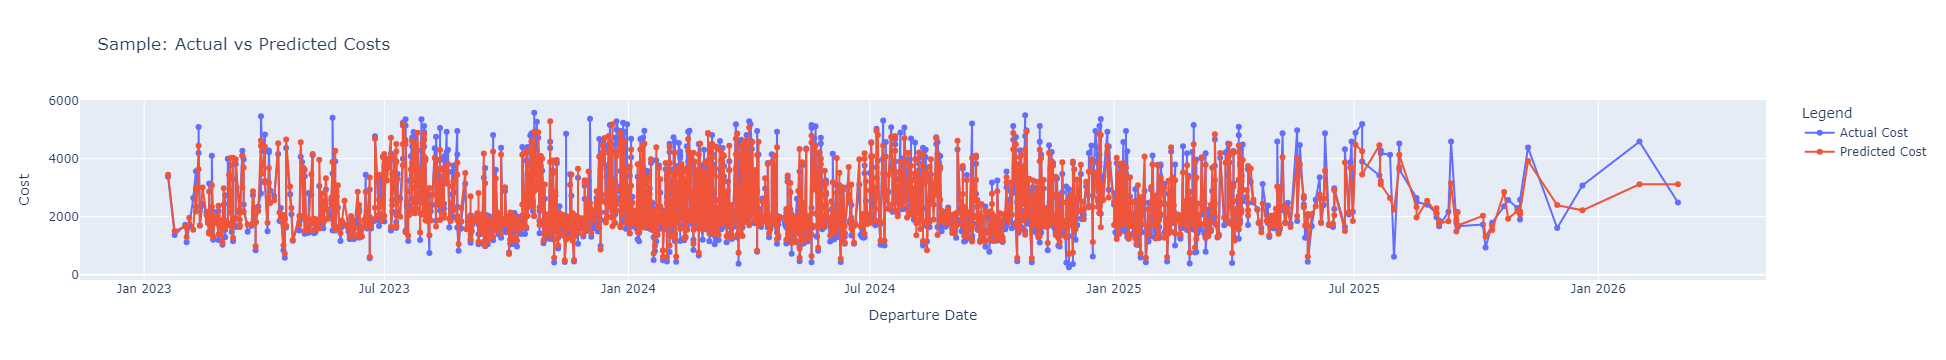

In [63]:
import plotly.graph_objects as go

# Create the interactive plot of Actual vs Predicted costs
test_df = X_test.copy()
test_df[target] = y_test
test_df['PREDICTED_COST'] = predictions
test_df['DEP_DATE'] = df.loc[X_test.index, 'DEP_DATE']

# Sample a subset of the test data for visualization
sample_df = test_df.sample(n=2000, random_state=1)  # Adjust sample size as needed
sample_df = sample_df.sort_values(by='DEP_DATE')
# Create the interactive plot
fig = go.Figure()

# Add Actual Cost trace
fig.add_trace(go.Scatter(
    x=sample_df['DEP_DATE'],
    y=sample_df[target],
    mode='lines+markers',
    name='Actual Cost'
))

# Add Predicted Cost trace
fig.add_trace(go.Scatter(
    x=sample_df['DEP_DATE'],
    y=sample_df['PREDICTED_COST'],
    mode='lines+markers',
    name='Predicted Cost'
))

# Update layout for better readability
fig.update_layout(
    title='Sample: Actual vs Predicted Costs',
    xaxis_title='Departure Date',
    yaxis_title='Cost',
    legend_title='Legend'
)

# Show the plot
fig.show()

In [25]:
# Assuming `model` is your trained XGBoost model
booster = model.get_booster()
importance = booster.get_score(importance_type='weight')

# Convert the importance dictionary to a sorted list of tuples
importance_sorted = sorted(importance.items(), key=lambda item: item[1], reverse=True)

# Print the feature importance values
for feature, score in importance_sorted:
    print(f"Feature: {feature}, Score: {score}")


Feature: NEW_BOOKED_DATE, Score: 81746.0
Feature: DAYS_IN_BETWEEN, Score: 59297.0
Feature: NEW_DEP_DATE, Score: 58616.0
Feature: BCLASS_DEP_DATE, Score: 46442.0
Feature: AIRLINE_ROUTE_BCLASS_CCLASS, Score: 43150.0
Feature: ROUTE, Score: 42478.0
Feature: DEP_MONTH_ROUTE, Score: 42412.0
Feature: BOOKING_CLASS, Score: 41512.0
Feature: NEW_DES_DATE, Score: 39502.0
Feature: DEP_DES_DAYS, Score: 32265.0
Feature: DAY_OF_WEEK, Score: 21629.0
Feature: ADULT, Score: 20130.0
Feature: FARE_TYPE, Score: 15471.0
Feature: CHILD, Score: 13900.0
Feature: TOTAL_PASSENGERS, Score: 13305.0
Feature: AIRLINE, Score: 13274.0
Feature: CABIN_CLASS, Score: 6523.0
Feature: HIGH_SEASON_EVENTS, Score: 171.0


In [88]:
from datetime import date, timedelta

sample_booking = {
    'BOOKED_DATE': '2024-08-21',
    'DEP_DATE': '2025-07-01',
    'DES_DATE': '2025-08-31',
    'ADULT': 1,
    'CHILD': 0,
    'INFANT': 0,
    'CABIN_CLASS': 'economy',
    'FARE_TYPE': 'ITX',
    'BOOKING_CLASS': 'L',
    'ROUTE': 'lgw -> anu -> anu -> lgw',
    'AIRLINE': 'BA',
}

# Convert the sample booking into a DataFrame
sample_df = pd.DataFrame([sample_booking])


sample_df['BOOKED_DATE'] = pd.to_datetime(sample_df['BOOKED_DATE'])
sample_df['DEP_DATE'] = pd.to_datetime(sample_df['DEP_DATE'])

# Add 50 days to the booked date for prediction purposes
sample_df['BOOKED_DATE'] = sample_df['BOOKED_DATE'] + pd.Timedelta(days=50)

# Calculate DAYS_IN_BETWEEN for future predictions
sample_df['DAYS_IN_BETWEEN'] = (sample_df['DEP_DATE'] - sample_df['BOOKED_DATE']).dt.days
# Extract date components
sample_df['BOOKED_YEAR'] = sample_df['BOOKED_DATE'].dt.year
sample_df['BOOKED_MONTH'] = sample_df['BOOKED_DATE'].dt.month
sample_df['BOOKED_DAY'] = sample_df['BOOKED_DATE'].dt.day
sample_df['DEP_YEAR'] = sample_df['DEP_DATE'].dt.year
sample_df['DEP_MONTH'] = sample_df['DEP_DATE'].dt.month
sample_df['DEP_DAY'] = sample_df['DEP_DATE'].dt.day
sample_df['DES_DATE'] = pd.to_datetime(sample_df['DES_DATE'])
sample_df['DES_YEAR'] = sample_df['DES_DATE'].dt.year
sample_df['DES_MONTH'] = sample_df['DES_DATE'].dt.month
sample_df['DES_DAY'] = sample_df['DES_DATE'].dt.day
sample_df['DEP_DES_DAYS'] = (sample_df['DES_DATE'] - sample_df['DEP_DATE']).dt.days
sample_df['DAY_OF_WEEK'] = sample_df['DEP_DATE'].dt.dayofweek

sample_df['NEW_BOOKED_DATE'] = sample_df['BOOKED_DATE'].astype('int64')
sample_df['NEW_DEP_DATE'] = sample_df['DEP_DATE'].astype('int64')
sample_df['NEW_DES_DATE'] = sample_df['DES_DATE'].astype('int64')

sample_df = mark_high_season_events(sample_df, dep_date_col='DEP_DATE')
sample_df['TOTAL_PASSENGERS'] = sample_df['ADULT'] + sample_df['CHILD'] + sample_df['INFANT']
sample_df['BCLASS_DEP_DATE'] = sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['DEP_MONTH'].astype(str) + '_' + sample_df['DEP_DAY'].astype(str)
sample_df['AIRLINE_ROUTE_BCLASS_CCLASS'] = sample_df['AIRLINE'].astype(str) + '_' + sample_df['ROUTE'].astype(str) + '_' + sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['CABIN_CLASS'].astype(str)
sample_df['BOOKING_CLASS_DAYS_IN_BETWEEN'] = sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['DAYS_IN_BETWEEN'].astype(str)
sample_df['DEP_MONTH_ROUTE'] = sample_df['DEP_MONTH'].astype(str) + '_' + sample_df['ROUTE'].astype(str)
sample_df['MONTHROUTE_BCLASSMONTHS'] = sample_df['DEP_MONTH_ROUTE'].astype(str) + '_' + sample_df['BOOKING_CLASS'].astype(str) + '_' + sample_df['BOOKED_MONTH'].astype(str)
sample_df['MONTH_ROUTE_FARETYPE_BCLASSDAYS'] = sample_df['BOOKED_MONTH'].astype(str) + '_' + sample_df['ROUTE'].astype(str) + '_' + sample_df['FARE_TYPE'].astype(str) + '_' + sample_df['BOOKING_CLASS_DAYS_IN_BETWEEN'].astype(str)

sample_df = sample_df.apply(lambda col: col.str.lower() if col.dtype == 'object' else col)

# Apply LabelEncoder to the label features (same as training)
for feature in label_features:
    le = label_encoders[feature]
    sample_df[feature] = sample_df[feature].apply(lambda x: le.transform([x])[0] if x in le.classes_ else -1)

# Prepare features for prediction
features = ['ADULT', 'CHILD','ROUTE','AIRLINE','BOOKING_CLASS','CABIN_CLASS','FARE_TYPE', 'NEW_BOOKED_DATE', 'NEW_DEP_DATE', 'NEW_DES_DATE','DEP_DES_DAYS','DAYS_IN_BETWEEN','TOTAL_PASSENGERS'
            ,'BCLASS_DEP_DATE', 'AIRLINE_ROUTE_BCLASS_CCLASS','HIGH_SEASON_EVENTS', 'DEP_MONTH_ROUTE', 'DAY_OF_WEEK'
           ]
# Predict the cost for this single booking
predicted_cost = model.predict(sample_df[features])

sample_df['PREDICTED_COST'] = predicted_cost

print(sample_df[['DEP_DATE', 'PREDICTED_COST']])

    DEP_DATE  PREDICTED_COST
0 2025-07-01     1278.255737


In [78]:
sample_df.head()

,BOOKED_DATE,DEP_DATE,DES_DATE,ADULT,CHILD,INFANT,CABIN_CLASS,FARE_TYPE,BOOKING_CLASS,ROUTE,...,NEW_DES_DATE,HIGH_SEASON_EVENTS,TOTAL_PASSENGERS,BCLASS_DEP_DATE,AIRLINE_ROUTE_BCLASS_CCLASS,BOOKING_CLASS_DAYS_IN_BETWEEN,DEP_MONTH_ROUTE,MONTHROUTE_BCLASSMONTHS,MONTH_ROUTE_FARETYPE_BCLASSDAYS,PREDICTED_COST
0,2024-10-10,2025-05-01,2025-05-23,1,0,0,1,0,17,-1,...,1747958400000000000,14,1,4887,-1,s_203,-1,-1,-1,1141.35083


In [28]:
sample_df.to_csv('sample.csv')